# NumCompute-Stream demo

Stream a CSV file through a decision-tree pipeline that learns chunk by chunk, then log and plot how it performs over time.

The main data is `demo/data/stream.csv`: 20,000 synthetic rows written by `demo/generate_stream.py` (fixed seed). It has:

- an abrupt concept drift at row 10,000 (chunk 100): the label rule changes from `x0 + x1 > 0` to `x2 - x4 > 0`;
- a gradual drift in `x3`, whose mean moves from 0 to 3;
- about 3% missing `x2` cells and 5% flipped labels;
- a `segment` column whose category `D` only appears after the drift.

Section 9 repeats the stream on a real dataset (banknote authentication).

## 0. Setup

From the project root, install with `python -m pip install -e ".[test,demo]"`, select that environment as the kernel and choose **Run All**. The working directory can be the project root or `demo/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd() if (Path.cwd() / "numcompute_stream").is_dir() else Path.cwd().parent
sys.path.insert(0, str(root))

import numcompute_stream
from numcompute_stream import io
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import OneHotEncoder, SimpleImputer, StandardScaler
from numcompute_stream.stats import StreamingStats
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.visualise import compare_models, plot_metric_over_time, plot_predictions_vs_ground_truth

DATA = root / "demo" / "data"
STREAM_CSV = DATA / "stream.csv"
FEATURES = ["x0", "x1", "x2", "x3", "x4"]
CHUNK = 100                          # rows per chunk
DRIFT_CHUNK = 10_000 // CHUNK        # the label rule changes at row 10,000

np.set_printoptions(precision=3, suppress=True)
print(f"numcompute_stream {numcompute_stream.__version__} | numpy {np.__version__}")

numcompute_stream 0.2.0 | numpy 2.5.4


## 1. Load the stream

A first look at the whole file with `io.load_csv`. The training below never loads it at once.

In [2]:
header = io.read_header(STREAM_CSV)
X_all = io.load_csv(STREAM_CSV, usecols=FEATURES, dtype=float)       # empty cells become NaN
y_all = io.load_csv(STREAM_CSV, usecols="label", dtype=int).ravel()
labels, label_counts = np.unique(y_all, return_counts=True)
segments, segment_counts = np.unique(io.load_csv(STREAM_CSV, usecols="segment"), return_counts=True)

print("Columns:", header)
print(f"Rows: {len(y_all):,} -> {len(y_all) // CHUNK} chunks of {CHUNK}")
print("Missing cells per feature:", dict(zip(FEATURES, np.isnan(X_all).sum(axis=0).tolist())))
print("Label counts:", dict(zip(labels.tolist(), label_counts.tolist())))
print("Segment counts:", dict(zip(segments.tolist(), segment_counts.tolist())))

Columns: ['x0', 'x1', 'x2', 'x3', 'x4', 'segment', 'label']
Rows: 20,000 -> 200 chunks of 100
Missing cells per feature: {'x0': 0, 'x1': 0, 'x2': 580, 'x3': 0, 'x4': 0}
Label counts: {0: 10025, 1: 9975}
Segment counts: {'A': 5871, 'B': 5760, 'C': 5862, 'D': 2507}


## 2. Stream and train

`io.iter_csv_chunks` reads the file 100 rows at a time. Each chunk goes through imputer → scaler → tree with `partial_fit`: the imputer and scaler update their running statistics, and the tree adds the rows to its buffer and retrains every 500 rows (5 chunks).

`StreamTrainer` evaluates test-then-train: each chunk is scored by the current model before the model learns from it, so every score is on unseen rows. All chunks are logged in `history_`; the printed log shows the first chunks and the ones around the drift.

In [3]:
def csv_stream(path, features, target, chunk_size):
    """Yield (X, y) chunks read lazily from a CSV file."""
    for chunk in io.iter_csv_chunks(path, chunk_size, usecols=[*features, target], dtype=float):
        yield chunk[:, :-1], chunk[:, -1].astype(int)


def make_pipeline(buffer_size=500):
    """Imputer -> scaler -> buffered decision tree, all learning with partial_fit."""
    return Pipeline([
        ("impute", SimpleImputer()),
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=5, buffer_size=buffer_size)),
    ])

In [4]:
pipe = make_pipeline(buffer_size=500)
tree = pipe.steps[-1][1]
trainer = StreamTrainer(pipe, window=10)
shown = set(range(8)) | set(range(DRIFT_CHUNK - 2, DRIFT_CHUNK + 8))       # chunks printed below

for X, y in csv_stream(STREAM_CSV, FEATURES, "label", CHUNK):
    chunk = len(trainer.history_["chunk"])
    trainer.verbose = chunk in shown
    if chunk == DRIFT_CHUNK - 2:
        print("...")
    y_pred = pipe.predict(X) if hasattr(tree, "classes_") else None        # kept for section 5
    trainer.process_chunk(X, y)

history = trainer.history_
last_y, last_pred = y, y_pred
print(f"\n{len(history['chunk'])} chunks, {tree.n_retrains_} retrains, "
      f"final cumulative accuracy {history['cumulative_accuracy'][-1]:.3f}")

chunk    0 | n   100 | acc nan | cum nan | roll nan | retrained      -   | buffer     4.7 kB
chunk    1 | n   100 | acc nan | cum nan | roll nan | retrained      -   | buffer     9.4 kB
chunk    2 | n   100 | acc nan | cum nan | roll nan | retrained      -   | buffer    14.1 kB
chunk    3 | n   100 | acc nan | cum nan | roll nan | retrained      -   | buffer    18.8 kB
chunk    4 | n   100 | acc nan | cum nan | roll nan | retrained    3.9 ms | buffer     0.0 kB
chunk    5 | n   100 | acc 0.930 | cum 0.930 | roll 0.930 | retrained      -   | buffer     4.7 kB
chunk    6 | n   100 | acc 0.900 | cum 0.915 | roll 0.915 | retrained      -   | buffer     9.4 kB
chunk    7 | n   100 | acc 0.870 | cum 0.900 | roll 0.900 | retrained      -   | buffer    14.1 kB
...
chunk   98 | n   100 | acc 0.870 | cum 0.890 | roll 0.864 | retrained      -   | buffer    18.8 kB
chunk   99 | n   100 | acc 0.920 | cum 0.890 | roll 0.874 | retrained    3.5 ms | buffer     0.0 kB
chunk  100 | n   100 | acc 0.530 |

The tree cannot predict before its first retrain (chunk 4), so the first five scores are NaN. After the drift at chunk 100 the old tree is right only about half the time, until the retrain at chunk 104 learns from the 500 rows that arrived after the drift.

## 3. Metrics over time

Accuracy over the whole stream, the error rate around the drift with the retrains marked, the cumulative F1 and AUC, and the memory held by the buffer.

Mean accuracy, chunks 10-99 (before the drift): 0.890
Mean accuracy, chunks 100-104 (just after):     0.498
Mean accuracy, chunks 110-199 (recovered):      0.874


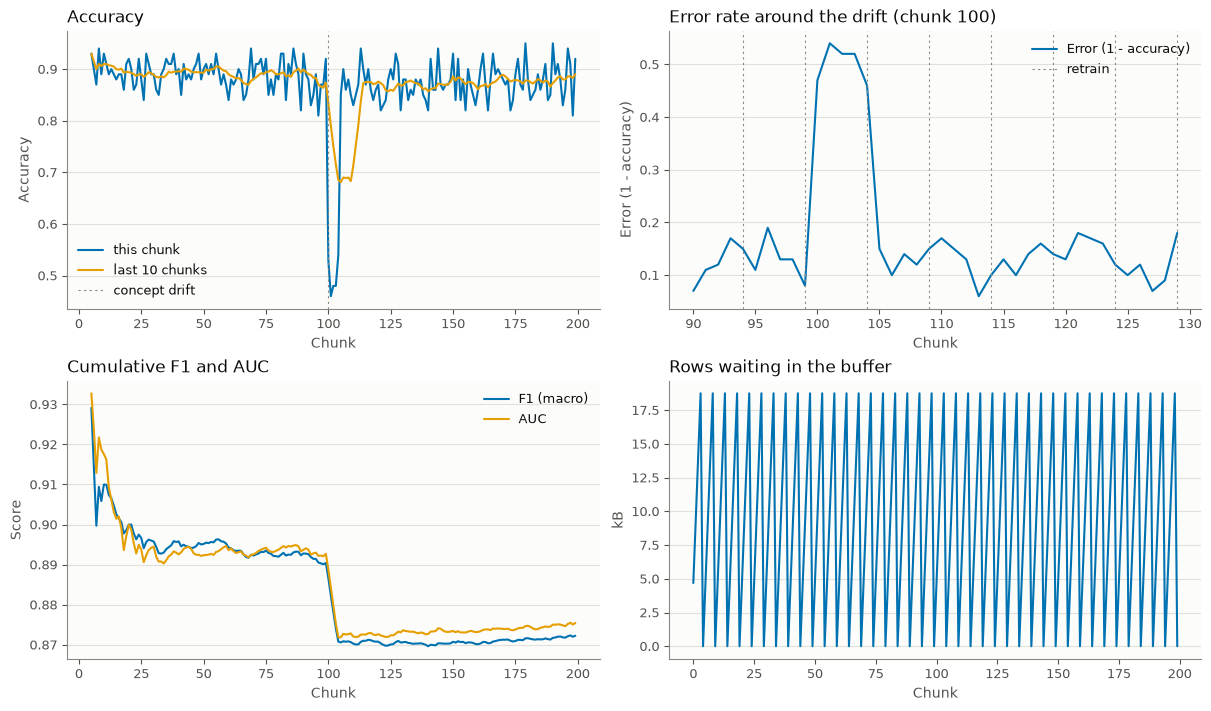

In [5]:
acc = np.asarray(history["accuracy"])
near = np.arange(DRIFT_CHUNK - 10, DRIFT_CHUNK + 30)                       # chunks 90-129
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")

plot_metric_over_time({"this chunk": history["accuracy"], "last 10 chunks": history["rolling_accuracy"]},
                      title="Accuracy", ylabel="Accuracy", events=[DRIFT_CHUNK],
                      events_label="concept drift", ax=axes[0, 0])
plot_metric_over_time(1 - acc[near], x=near, title=f"Error rate around the drift (chunk {DRIFT_CHUNK})",
                      ylabel="Error (1 - accuracy)", events=near[np.asarray(history["retrained"])[near]],
                      events_label="retrain", ax=axes[0, 1])
plot_metric_over_time({"F1 (macro)": history["cumulative_f1"], "AUC": history["cumulative_auc"]},
                      title="Cumulative F1 and AUC", ylabel="Score", ax=axes[1, 0])
plot_metric_over_time(np.asarray(history["buffer_bytes"]) / 1024, title="Rows waiting in the buffer",
                      ylabel="kB", ax=axes[1, 1])

print(f"Mean accuracy, chunks 10-99 (before the drift): {np.nanmean(acc[10:DRIFT_CHUNK]):.3f}")
print(f"Mean accuracy, chunks 100-104 (just after):     {np.nanmean(acc[DRIFT_CHUNK:DRIFT_CHUNK + 5]):.3f}")
print(f"Mean accuracy, chunks 110-199 (recovered):      {np.nanmean(acc[DRIFT_CHUNK + 10:]):.3f}")

Before the drift accuracy is about 0.89; the 5% flipped labels keep it below 0.95. It falls to 0.50 (chance) for the five chunks after the drift and is back near 0.87 after one retrain. The cumulative F1 and AUC keep the drop for the rest of the stream, so the rolling accuracy is the better signal of current performance. The buffer grows by 4.7 kB per chunk and empties at each retrain, so it holds at most 18.8 kB between retrains and 23.4 kB (500 rows) just before one, however long the stream is.

## 4. Model comparison: buffer size

The same stream through pipelines that differ only in `buffer_size`. A small buffer retrains often on little data; a large one trains on more rows but reacts late to the drift.

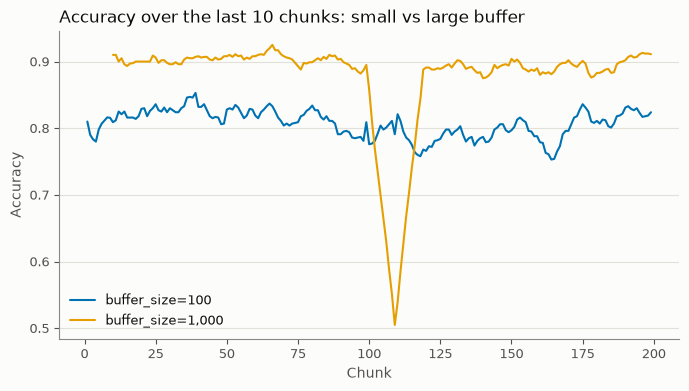

In [6]:
def run_stream(buffer_size):
    """History of a fresh pipeline streamed over stream.csv."""
    return StreamTrainer(make_pipeline(buffer_size), window=10).run(
        csv_stream(STREAM_CSV, FEATURES, "label", CHUNK), flush=False)


runs = {500: history} | {size: run_stream(size) for size in (100, 1000, 2000, 5000)}

compare_models(runs[100]["rolling_accuracy"], runs[1000]["rolling_accuracy"],
               labels=("buffer_size=100", "buffer_size=1,000"),
               title="Accuracy over the last 10 chunks: small vs large buffer", ylabel="Accuracy");

buffer_size | retrains | retrain time | accuracy after drift
        100 |      200 |     302.8 ms | 0.797
        500 |       40 |     177.0 ms | 0.855
      1,000 |       20 |     198.9 ms | 0.854
      2,000 |       10 |     168.7 ms | 0.823
      5,000 |        4 |     153.3 ms | 0.710


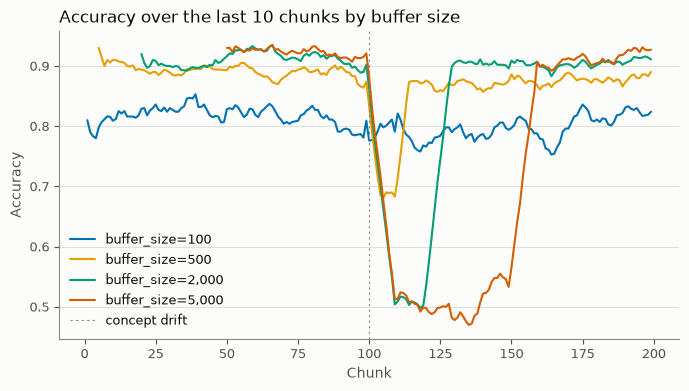

In [7]:
print("buffer_size | retrains | retrain time | accuracy after drift")
for size in sorted(runs):
    h = runs[size]
    print(f"{size:11,} | {h['n_retrains'][-1]:8} | {np.nansum(h['retrain_time']) * 1000:9.1f} ms "
          f"| {np.nanmean(h['accuracy'][DRIFT_CHUNK:]):.3f}")

plot_metric_over_time({f"buffer_size={s:,}": runs[s]["rolling_accuracy"] for s in (100, 500, 2000, 5000)},
                      title="Accuracy over the last 10 chunks by buffer size", ylabel="Accuracy",
                      events=[DRIFT_CHUNK], events_label="concept drift");

`buffer_size=100` retrains every chunk, so it barely notices the drift, but each tree sees only 100 rows and stays near 0.80. Larger buffers give better trees but keep the old rule until their next retrain: `buffer_size=2,000` recovers at chunk 120 and `buffer_size=5,000` only at chunk 150 (0.710 after the drift). 500 to 1,000 rows balance the two (about 0.855). Total retraining time generally falls as the buffer grows: fewer, larger fits cost less than many small ones.

## 5. Predictions on the latest chunk

The last chunk of the stream, predicted by the model as it was before it learned from that chunk. Left: the first 40 rows (wrong predictions are crossed). Right: the confusion matrix of all 100 rows.

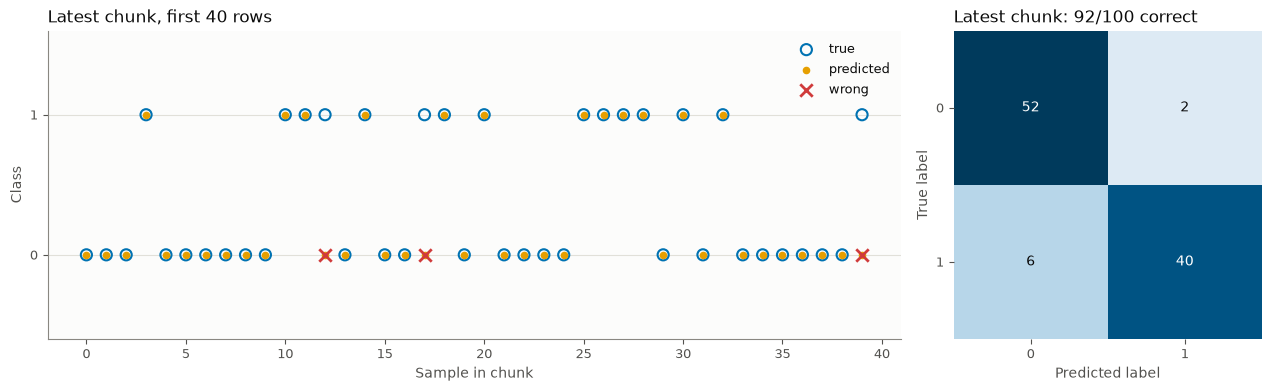

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained", width_ratios=(2.2, 1))
plot_predictions_vs_ground_truth(last_y[:40], last_pred[:40], title="Latest chunk, first 40 rows", ax=axes[0])
plot_predictions_vs_ground_truth(last_y, last_pred, kind="confusion", ax=axes[1]);

## 6. Inside the tree

The tree trained on the last 500 rows. Its inputs are scaled by the pipeline, so thresholds are in standardised units.

In [9]:
print(f"Depth {tree.depth_}, {tree.n_leaves_} leaves, {tree.n_retrains_} retrains, memory {tree.memory_usage()} bytes")
print(tree.export_text(feature_names=FEATURES))

Depth 5, 24 leaves, 40 retrains, memory {'buffer': 0, 'tree': 4512} bytes
|--- x4 <= -0.221
|   |--- x2 <= -0.896
|   |   |--- x4 <= -1.021
|   |   |   |--- x2 <= -1.439
|   |   |   |   |--- x2 <= -1.852
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- x2 >  -1.852
|   |   |   |   |   |--- class: 0
|   |   |   |--- x2 >  -1.439
|   |   |   |   |--- x2 <= -0.962
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- x2 >  -0.962
|   |   |   |   |   |--- class: 0
|   |   |--- x4 >  -1.021
|   |   |   |--- x3 <= 1.742
|   |   |   |   |--- class: 0
|   |   |   |--- x3 >  1.742
|   |   |   |   |--- x0 <= -0.452
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- x0 >  -0.452
|   |   |   |   |   |--- class: 1
|   |--- x2 >  -0.896
|   |   |--- x3 <= 2.454
|   |   |   |--- x2 <= -0.382
|   |   |   |   |--- x4 <= -0.737
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- x4 >  -0.737
|   |   |   |   |   |--- class: 0
|   |   |   |--- x2 >  -0.382
|   |   |   |   |--- x0 <= -1.000
|

The root splits on `x4` and the next level on `x2`: the tree has learned the post-drift rule `x2 - x4 > 0`. Lower splits on `x0`, `x1` and `x3` fit noise. Some sibling leaves predict the same class: those splits lower the impurity without changing the majority class.

## 7. Streaming statistics

`StreamingStats.update_stats` summarises each chunk in fixed memory. One instance covers the whole stream; another keeps only the last 10 chunks (`window=10`), so it follows the gradual drift in `x3`.

Rows: whole 20,000, window 1,000
Missing x2 cells (whole stream): 580
x3 quantiles 10/50/90%, whole stream:   [-0.233  1.509  3.209]
x3 quantiles 10/50/90%, last 10 chunks: [1.558 2.886 4.206]
Std per feature, whole stream: [1.005 1.005 0.989 1.326 1.013]


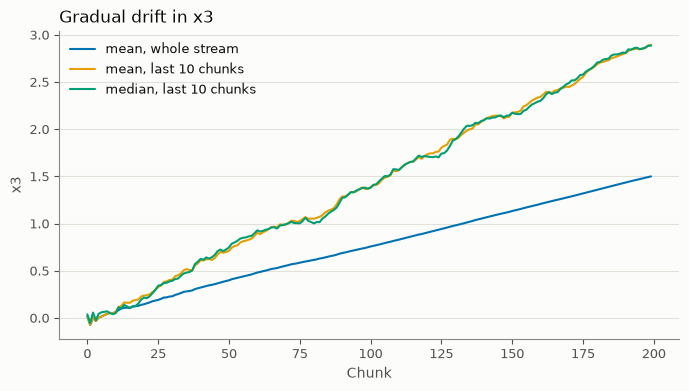

In [10]:
whole, recent = StreamingStats(), StreamingStats(window=10)
x3 = {"mean, whole stream": [], "mean, last 10 chunks": [], "median, last 10 chunks": []}

for X_chunk, _ in csv_stream(STREAM_CSV, FEATURES, "label", CHUNK):
    whole.update_stats(X_chunk)
    recent.update_stats(X_chunk)
    x3["mean, whole stream"].append(whole.mean()[3])
    x3["mean, last 10 chunks"].append(recent.mean()[3])
    x3["median, last 10 chunks"].append(recent.quantile(0.5)[3])

plot_metric_over_time(x3, title="Gradual drift in x3", ylabel="x3")

print(f"Rows: whole {whole.n_:,}, window {recent.n_:,}")
print("Missing x2 cells (whole stream):", whole.n_ - whole.count_[2])
print("x3 quantiles 10/50/90%, whole stream:  ", whole.quantile([0.1, 0.5, 0.9])[:, 3])
print("x3 quantiles 10/50/90%, last 10 chunks:", recent.quantile([0.1, 0.5, 0.9])[:, 3])
print("Std per feature, whole stream:", whole.std())

The whole-stream mean ends at 1.5, half the current level, because it averages all 20,000 rows. The windowed mean and median follow `x3` to about 2.9. The quantiles show the same shift, and `x3` has the largest standard deviation because the drift spreads its values over time. The 580 missing `x2` cells match section 1: `StreamingStats` skips NaN cell by cell.

## 8. New categories mid-stream

The `segment` column streamed through `OneHotEncoder` → tree. When category `D` first appears, the encoder adds a column at the end of its output, and the pipeline calls `tree.add_features(1)` so the rows already in the buffer get a zero in that column. The label does not depend on `segment`; this section only shows the two growing together.

In [11]:
encoder, seg_tree = OneHotEncoder(), DecisionTreeClassifier(max_depth=3, buffer_size=500)
seg_pipe = Pipeline([("encode", encoder), ("tree", seg_tree)])
n_columns = 0

for i, chunk in enumerate(io.iter_csv_chunks(STREAM_CSV, CHUNK, usecols=["segment", "label"])):
    seg_pipe.partial_fit(chunk[:, :1], chunk[:, 1].astype(int))
    if encoder.n_features_out_ != n_columns:
        n_columns = encoder.n_features_out_
        print(f"chunk {i:3d}: categories {encoder.categories_[0].tolist()} -> {n_columns} columns, "
              f"tree n_features_in_ = {getattr(seg_tree, 'n_features_in_', 'not trained yet')}")

print(f"After the stream: tree n_features_in_ = {seg_tree.n_features_in_}")
print("Encoding of A and D:\n", encoder.transform(np.array([["A"], ["D"]])))
print("Predictions for rows with D:", seg_pipe.predict(np.array([["D"]] * 3)))

chunk   0: categories ['A', 'B', 'C'] -> 3 columns, tree n_features_in_ = not trained yet
chunk 100: categories ['A', 'B', 'C', 'D'] -> 4 columns, tree n_features_in_ = 4
After the stream: tree n_features_in_ = 4
Encoding of A and D:
 [[1. 0. 0. 0.]
 [0. 0. 0. 1.]]
Predictions for rows with D: [1 1 1]


## 9. Real data: banknote authentication

Lohweg, V. (2012). *Banknote Authentication* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55P57 (CC BY 4.0).

1,372 banknote images described by 4 wavelet features (`variance`, `skewness`, `curtosis`, `entropy`) and a binary `class`. The original file is sorted by class, so `demo/data/banknote.csv` holds the rows shuffled with seed 42, with a header added. It is streamed in chunks of 50 through scaler → tree (`buffer_size=200`).

28 chunks, 6 retrains | cumulative accuracy 0.942, F1 0.941, AUC 0.953


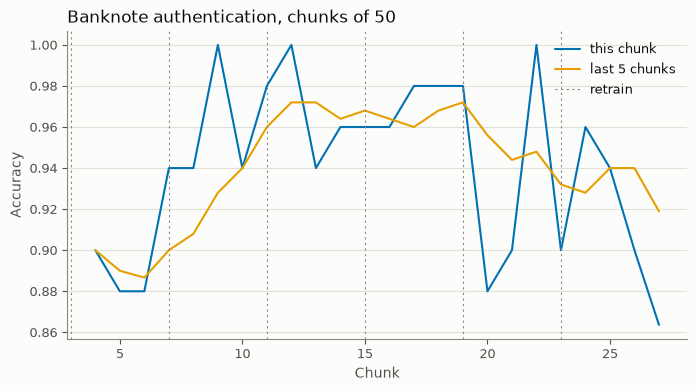

In [12]:
BANKNOTE_CSV = DATA / "banknote.csv"
bank_features = io.read_header(BANKNOTE_CSV)[:-1]
bank_pipe = Pipeline([("scale", StandardScaler()), ("tree", DecisionTreeClassifier(max_depth=5, buffer_size=200))])
bank = StreamTrainer(bank_pipe, window=5).run(csv_stream(BANKNOTE_CSV, bank_features, "class", 50))

print(f"{len(bank['chunk'])} chunks, {bank['n_retrains'][-1]} retrains | cumulative accuracy "
      f"{bank['cumulative_accuracy'][-1]:.3f}, F1 {bank['cumulative_f1'][-1]:.3f}, AUC {bank['cumulative_auc'][-1]:.3f}")
plot_metric_over_time({"this chunk": bank["accuracy"], "last 5 chunks": bank["rolling_accuracy"]},
                      title="Banknote authentication, chunks of 50", ylabel="Accuracy",
                      events=bank["retrained"], events_label="retrain");

With no drift, accuracy stays high throughout (0.94 cumulative, AUC 0.95), unlike the collapse in section 3. Chunks hold only 50 rows, so one or two mistakes move the per-chunk accuracy by 2 to 4 points.

## 10. Benchmarks

Results saved by `python -m benchmark.run_stream_benchmarks` (see `benchmark/stream_results.md`); they are read from file here, not re-run.


Loop vs vectorised
| Operation | NumCompute result | Baseline/result |
|---|---:|---:|
| tree root split (max_depth=1) n=5,000 d=5 | 11.377 ms | 36.694 ms (3.2x) |
| tree fit max_depth=5 n=5,000 d=5 | 38.637 ms | 158.445 ms (4.1x) |
| tree predict n=20,000 | 2.236 ms | 16.935 ms (7.6x) |
| streaming mean/var 100,000 x 5 in chunks of 1,000 | 30.087 ms | 132.784 ms (4.4x) |

buffer_size sweep
| buffer_size | Retrains | Total retrain time | Mean retrain time | Final cumulative accuracy | Mean accuracy after drift | Buffer between retrains |
|---:|---:|---:|---:|---:|---:|---:|
| 100 | 200 | 396.3 ms | 1.98 ms | 0.808 | 0.797 | 0.0 kB |
| 250 | 66 | 276.4 ms | 4.19 ms | 0.853 | 0.838 | 9.4 kB |
| 500 | 40 | 238.8 ms | 5.97 ms | 0.872 | 0.855 | 18.8 kB |
| 1,000 | 20 | 182.9 ms | 9.14 ms | 0.877 | 0.854 | 42.2 kB |
| 2,000 | 10 | 147.8 ms | 14.78 ms | 0.862 | 0.823 | 89.1 kB |
| 5,000 | 4 | 143.0 ms | 35.76 ms | 0.781 | 0.710 | 229.7 kB |


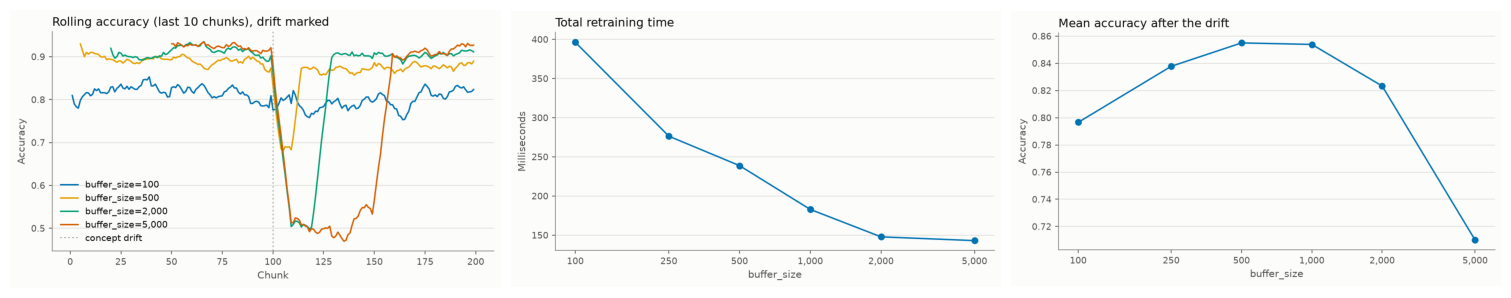

In [13]:
report = (root / "benchmark" / "stream_results.md").read_text(encoding="utf-8")
for line in report.splitlines():
    if line.startswith(("## Loop", "## buffer")):
        print("\n" + line[3:])
    elif line.startswith("|"):
        cells = line.split("|")
        print("|".join(cells[:4] + [""]) if len(cells) == 6 else line)      # drop the long Notes column

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for ax, name in zip(axes, ["rolling_accuracy.png", "retrain_time.png", "accuracy_after_drift.png"]):
    ax.imshow(plt.imread(root / "benchmark" / "figures" / name))
    ax.axis("off")

The vectorised split search, prediction and streaming moments are 3 to 8 times faster than the same algorithms written with Python loops (timings depend on the machine). The sweep repeats section 4 with more sizes: accuracy after the drift peaks at 500 to 1,000 rows, while total retraining time keeps falling as the buffer grows.

## Summary

- `io.iter_csv_chunks` → `Pipeline.partial_fit` → `StreamTrainer` learns from a 20,000-row CSV in chunks of 100, with memory bounded by the buffer.
- Test-then-train logging shows the drift at chunk 100 and the recovery at the next retrain.
- `buffer_size` trades reaction speed against data per tree; 500 to 1,000 works best on this stream.
- New categories, missing values and gradual drift are handled by the streaming preprocessing and statistics.